# PIA · Reporte de Inteligencia de Negocios
## Reseñas de recetas: lo que las estrellas no dicen

**Pregunta de negocio:** si el promedio de calificación de las recetas es casi perfecto, ¿de verdad no hay usuarios insatisfechos? Y si los hay, ¿de qué se quejan y qué recetas hay que atender primero?

La historia se cuenta en tres hallazgos:

| Hallazgo | Pregunta | Técnicas |
|---|---|---|
| 1. Insatisfacción oculta | ¿El texto revela insatisfacción que las estrellas no muestran? | Análisis de texto (TF-IDF) + Clasificación (regresión logística) |
| 2. De qué se quejan | ¿Qué temas concentran la insatisfacción? | Análisis de texto (modelado de temas NMF) + Kruskal-Wallis y χ² |
| 3. Qué recetas atender | ¿Qué recetas forman el grupo de riesgo? | Clustering (K-Means) + correlación de Spearman |

> Todas las cifras se reportan con **2 decimales truncados** (sin redondear). Las gráficas se guardan en la carpeta `figuras/`.

## 0. Preparación de los datos

Se limpia el HTML del texto (como en la Práctica 9) y se define una reseña **insatisfecha** como aquella con calificación válida de **1 a 3 estrellas**. Los comentarios sin calificación (`rating_valid == False`) no tienen estrellas, pero sí texto: son clave para el Hallazgo 1.

In [1]:
import re
import html
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup, MarkupResemblesLocatorWarning
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve, silhouette_score)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=MarkupResemblesLocatorWarning)
SEMILLA = 42

# Todas las cifras se reportan con 2 decimales TRUNCADOS (sin redondear).
def truncar(x, decimales=2):
    factor = 10 ** decimales
    if isinstance(x, (pd.Series, pd.DataFrame)):
        return np.trunc((x.astype(float) * factor).round(6)) / factor
    return float(np.trunc(round(float(x) * factor, 6)) / factor)

def tabla_truncada(tabla):
    tabla = tabla.copy()
    columnas = tabla.select_dtypes("float").columns
    tabla[columnas] = truncar(tabla[columnas])
    return tabla

def formato_p(p):
    """Valor p: 2 decimales truncados; si es muy pequeño, notación científica con mantisa truncada."""
    if p == 0:
        return "< 1e-300"
    if p >= 0.01:
        return f"{truncar(p):.2f}"
    exponente = int(np.floor(np.log10(p)))
    return f"{truncar(p / 10 ** exponente):.2f}e{exponente}"

pd.options.display.float_format = "{:.2f}".format

# Estilo de gráficas (las figuras se guardan en la carpeta figuras/ para la presentación)
AZUL, NARANJA, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
TEXTO, TEXTO_2, REJILLA, GRIS = "#0b0b0b", "#52514e", "#e4e3df", "#b9b8b1"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.dpi": 200,
    "font.family": "DejaVu Sans", "font.size": 11,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlecolor": TEXTO, "axes.labelcolor": TEXTO_2, "axes.edgecolor": GRIS,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": TEXTO_2, "ytick.color": TEXTO_2,
})
CARPETA_FIG = Path("figuras")
CARPETA_FIG.mkdir(exist_ok=True)

def guardar(fig, nombre):
    fig.savefig(CARPETA_FIG / f"{nombre}.png", bbox_inches="tight", facecolor="white")

In [2]:
RUTA_DATOS = Path("../Practica 1/dataset_limpio.csv")
if not RUTA_DATOS.exists():
    RUTA_DATOS = Path("dataset_limpio.csv")
df = pd.read_csv(RUTA_DATOS)

def limpiar_texto(valor):
    if pd.isna(valor):
        return ""
    texto = BeautifulSoup(html.unescape(str(valor)), "html.parser").get_text(" ")
    texto = texto.lower()
    texto = re.sub(r"https?://\S+|www\.\S+", " ", texto)
    texto = re.sub(r"[^a-z' ]", " ", texto)
    return re.sub(r"\s+", " ", texto).strip()

df["texto_limpio"] = df["text"].apply(limpiar_texto)
df["con_texto"] = df["texto_limpio"] != ""
# Reseña insatisfecha = calificación válida de 1 a 3 estrellas
df["insatisfecha"] = np.where(df["rating_valid"], (df["stars"] <= 3).astype(float), np.nan)

calificadas = df[df["rating_valid"] & df["con_texto"]].copy()
sin_calificacion = df[~df["rating_valid"] & df["con_texto"]].copy()

resumen = pd.Series({
    "Comentarios totales": len(df),
    "Recetas": df["recipe_name"].nunique(),
    "Reseñas con estrellas y texto": len(calificadas),
    "Comentarios con texto pero sin estrellas": len(sin_calificacion),
    "Promedio de estrellas": truncar(calificadas["stars"].mean()),
    "% reseñas de 5 estrellas": truncar((calificadas["stars"] == 5).mean() * 100),
    "% reseñas insatisfechas (1-3 estrellas)": truncar(calificadas["insatisfecha"].mean() * 100),
}, dtype=object)
display(resumen.to_frame("valor"))

,valor
Comentarios totales,18182
Recetas,100
Reseñas con estrellas y texto,16471
Comentarios con texto pero sin estrellas,1693
Promedio de estrellas,4.73
% reseñas de 5 estrellas,83.88
% reseñas insatisfechas (1-3 estrellas),6.07


### Punto de partida

El promedio es de **4.73 estrellas** y el **83.88 %** de las reseñas tiene 5 estrellas; solo el **6.07 %** está insatisfecha. Vista así, la plataforma no tendría ningún problema.

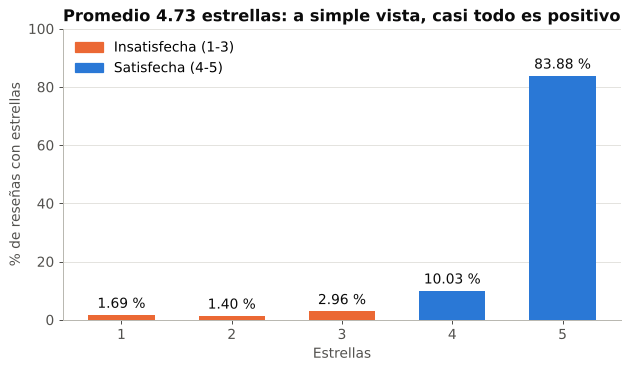

In [3]:
conteo = calificadas["stars"].value_counts().sort_index()
porcentaje = truncar(conteo / conteo.sum() * 100)

fig, ax = plt.subplots(figsize=(8, 4.2))
colores = [NARANJA if e <= 3 else AZUL for e in conteo.index]
barras = ax.bar(conteo.index.astype(str), porcentaje.values, color=colores, width=0.6)
ax.bar_label(barras, labels=[f"{p:.2f} %" for p in porcentaje.values], padding=3, color=TEXTO)
ax.set_ylim(0, 100)
ax.set_yticks(range(0, 101, 20))
ax.set_ylabel("% de reseñas con estrellas")
ax.set_xlabel("Estrellas")
ax.grid(axis="x", visible=False)
ax.set_title(f"Promedio {truncar(calificadas['stars'].mean()):.2f} estrellas: a simple vista, casi todo es positivo")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=NARANJA), plt.Rectangle((0, 0), 1, 1, color=AZUL)],
          labels=["Insatisfecha (1-3)", "Satisfecha (4-5)"], frameon=False, loc="upper left")
guardar(fig, "fig01_distribucion_estrellas")
plt.show()

## 1. Hallazgo 1: las estrellas esconden la insatisfacción

### 1.1 ¿El texto permite detectar a un usuario insatisfecho?

Se entrena un clasificador con el texto de las reseñas calificadas: el texto se convierte en un vector TF-IDF (palabras y pares de palabras) y una **regresión logística** aprende a separar reseñas insatisfechas (1-3★) de satisfechas (4-5★). Como solo el 6.07 % son insatisfechas, se usa `class_weight="balanced"`. El modelo se evalúa con el 20 % de reseñas que no vio durante el entrenamiento.

In [4]:
def nuevo_modelo():
    return Pipeline([
        ("tfidf", TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=3, sublinear_tf=True)),
        ("logit", LogisticRegression(max_iter=2000, class_weight="balanced", C=2)),
    ])

X_train, X_test, y_train, y_test = train_test_split(
    calificadas["texto_limpio"], calificadas["insatisfecha"].astype(int),
    test_size=0.20, random_state=SEMILLA, stratify=calificadas["insatisfecha"],
)
modelo = nuevo_modelo().fit(X_train, y_train)
prob_test = modelo.predict_proba(X_test)[:, 1]
pred_test = (prob_test >= 0.5).astype(int)

metricas_modelo = pd.Series({
    "AUC (ROC)": roc_auc_score(y_test, prob_test),
    "F1 macro": f1_score(y_test, pred_test, average="macro"),
    "Exactitud (accuracy)": accuracy_score(y_test, pred_test),
    "Recall de insatisfechas": recall_score(y_test, pred_test),
    "Precisión de insatisfechas": precision_score(y_test, pred_test),
})
print(f"Entrenamiento: {len(X_train):,} reseñas | Prueba: {len(X_test):,} reseñas")
display(truncar(metricas_modelo).to_frame("valor (conjunto de prueba)"))

Entrenamiento: 13,176 reseñas | Prueba: 3,295 reseñas


,valor (conjunto de prueba)
AUC (ROC),0.93
F1 macro,0.78
Exactitud (accuracy),0.94
Recall de insatisfechas,0.74
Precisión de insatisfechas,0.51


**AUC = 0.93:** si se toma al azar una reseña insatisfecha y una satisfecha, en 93 de cada 100 casos el modelo asigna mayor probabilidad de insatisfacción a la insatisfecha. Detecta el **74 %** de las reseñas insatisfechas (recall = 0.74); a cambio, cerca de la mitad de sus alertas (precisión = 0.51) son reseñas de 4-5★ que también contienen críticas o sugerencias.

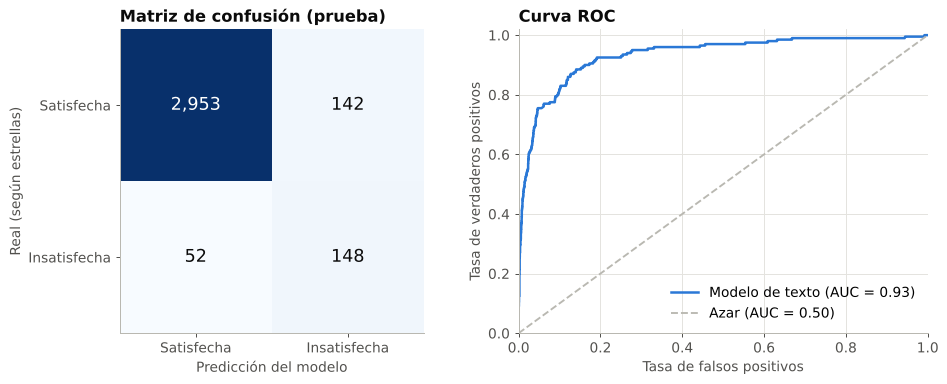

In [5]:
matriz = confusion_matrix(y_test, pred_test)
fpr, tpr, _ = roc_curve(y_test, prob_test)
auc = truncar(metricas_modelo["AUC (ROC)"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.4))
ax1.imshow(matriz, cmap="Blues")
etiquetas = ["Satisfecha", "Insatisfecha"]
for i in range(2):
    for j in range(2):
        ax1.text(j, i, f"{matriz[i, j]:,}", ha="center", va="center", fontsize=14,
                 color="white" if matriz[i, j] > matriz.max() / 2 else TEXTO)
ax1.set_xticks([0, 1], etiquetas)
ax1.set_yticks([0, 1], etiquetas)
ax1.set_xlabel("Predicción del modelo")
ax1.set_ylabel("Real (según estrellas)")
ax1.grid(False)
ax1.set_title("Matriz de confusión (prueba)")

ax2.plot(fpr, tpr, color=AZUL, linewidth=2, label=f"Modelo de texto (AUC = {auc:.2f})")
ax2.plot([0, 1], [0, 1], color=GRIS, linestyle="--", linewidth=1.5, label="Azar (AUC = 0.50)")
ax2.set_xlim(0, 1)
ax2.set_ylim(0, 1.02)
ax2.set_xticks(np.arange(0, 1.01, 0.2))
ax2.set_yticks(np.arange(0, 1.01, 0.2))
ax2.set_xlabel("Tasa de falsos positivos")
ax2.set_ylabel("Tasa de verdaderos positivos")
ax2.legend(frameon=False, loc="lower right")
ax2.set_title("Curva ROC")
fig.tight_layout()
guardar(fig, "fig02_desempeno_modelo")
plt.show()

### 1.2 ¿Qué palabras delatan la insatisfacción?

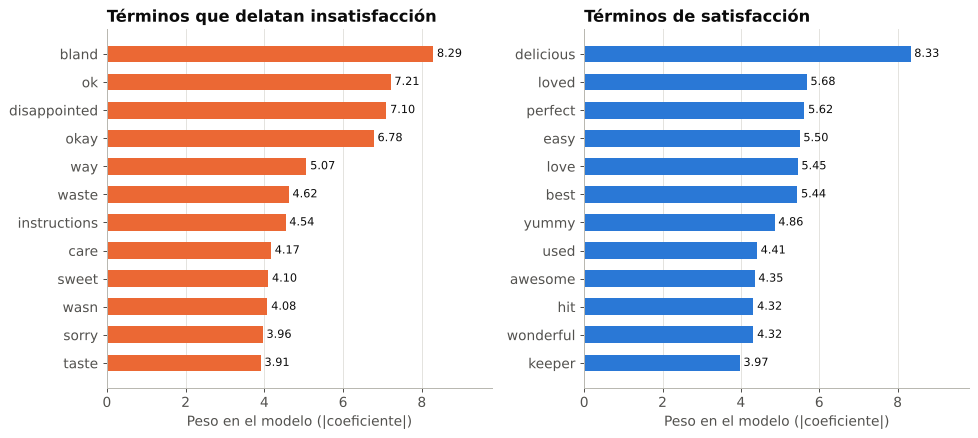

,insatisfacción,satisfacción
0,bland,delicious
1,ok,loved
2,disappointed,perfect
3,okay,easy
4,way,love
5,waste,best
6,instructions,yummy
7,care,used
8,sweet,awesome
9,wasn,hit


In [6]:
vectorizador = modelo.named_steps["tfidf"]
coeficientes = pd.Series(modelo.named_steps["logit"].coef_[0], index=vectorizador.get_feature_names_out())
# Para la gráfica solo se consideran términos que aparecen en al menos 30 reseñas (evita términos raros)
frecuencia_doc = pd.Series(np.asarray((vectorizador.transform(X_train) > 0).sum(axis=0)).ravel(),
                           index=coeficientes.index)
coef_frecuentes = coeficientes[frecuencia_doc >= 30]
top_insatisfaccion = coef_frecuentes.sort_values(ascending=False).head(12)
top_satisfaccion = coef_frecuentes.sort_values().head(12)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5))
for ax, serie, color, titulo in [
    (ax1, top_insatisfaccion, NARANJA, "Términos que delatan insatisfacción"),
    (ax2, top_satisfaccion.abs(), AZUL, "Términos de satisfacción"),
]:
    valores = truncar(serie)
    barras = ax.barh(valores.index[::-1], valores.values[::-1], color=color, height=0.6)
    ax.bar_label(barras, labels=[f"{v:.2f}" for v in valores.values[::-1]], padding=3, color=TEXTO, fontsize=9)
    ax.set_xlim(0, float(valores.max()) * 1.18)
    ax.set_xlabel("Peso en el modelo (|coeficiente|)")
    ax.grid(axis="y", visible=False)
    ax.set_title(titulo)
fig.tight_layout()
guardar(fig, "fig03_terminos_clave")
plt.show()
display(pd.DataFrame({"insatisfacción": top_insatisfaccion.index, "satisfacción": top_satisfaccion.index}))

Las palabras con más peso hacia la insatisfacción son *bland* (insípida), *ok/okay* (aceptable, sin entusiasmo), *disappointed*, *waste* (desperdicio), *sweet* (demasiado dulce) e *instructions*. Esta última indica que parte de las quejas son por **cómo está escrita la receta**, no solo por el sabor.

### 1.3 Insatisfacción en los comentarios sin estrellas

Hay **1,693 comentarios** con texto pero sin estrellas: no cuentan en el promedio. Se les aplica el modelo. Para comparar en igualdad de condiciones, las reseñas calificadas también se evalúan con el modelo mediante validación cruzada de 5 pliegues (cada reseña la evalúa un modelo que no la vio).

In [7]:
# Probabilidad de insatisfacción para TODAS las reseñas calificadas (validación cruzada de 5 pliegues:
# cada reseña se evalúa con un modelo que no la vio) y para los comentarios sin estrellas (modelo con todo).
pliegues = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
calificadas["prob_insatisfaccion"] = cross_val_predict(
    nuevo_modelo(), calificadas["texto_limpio"], calificadas["insatisfecha"].astype(int),
    cv=pliegues, method="predict_proba")[:, 1]
modelo_final = nuevo_modelo().fit(calificadas["texto_limpio"], calificadas["insatisfecha"].astype(int))
sin_calificacion["prob_insatisfaccion"] = modelo_final.predict_proba(sin_calificacion["texto_limpio"])[:, 1]

marcadas_calif = (calificadas["prob_insatisfaccion"] >= 0.5)
marcadas_sin = (sin_calificacion["prob_insatisfaccion"] >= 0.5)
tabla_2x2 = pd.DataFrame({
    "marcado insatisfecho": [marcadas_calif.sum(), marcadas_sin.sum()],
    "no marcado": [(~marcadas_calif).sum(), (~marcadas_sin).sum()],
}, index=["Reseñas con estrellas", "Comentarios sin estrellas"])
chi2_ocultos, p_ocultos, _, _ = stats.chi2_contingency(tabla_2x2)

comparacion = pd.Series({
    "Real: reseñas con 1-3 estrellas": calificadas["insatisfecha"].mean() * 100,
    "Modelo: reseñas con estrellas marcadas": marcadas_calif.mean() * 100,
    "Modelo: comentarios sin estrellas marcados": marcadas_sin.mean() * 100,
})
display(tabla_2x2)
display(truncar(comparacion).to_frame("% de insatisfacción"))
print(f"Chi-cuadrada (con vs sin estrellas): chi2 = {truncar(chi2_ocultos):.2f}, p = {formato_p(p_ocultos)}")
print(f"Razón de tasas: {truncar(comparacion.iloc[2] / comparacion.iloc[1]):.2f} veces")

,marcado insatisfecho,no marcado
Reseñas con estrellas,1478,14993
Comentarios sin estrellas,323,1370


,% de insatisfacción
Real: reseñas con 1-3 estrellas,6.07
Modelo: reseñas con estrellas marcadas,8.97
Modelo: comentarios sin estrellas marcados,19.07


Chi-cuadrada (con vs sin estrellas): chi2 = 174.38, p = 8.17e-40
Razón de tasas: 2.12 veces


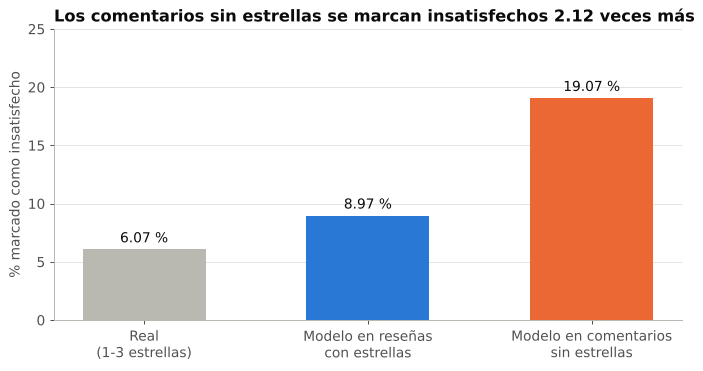

,recipe_name,texto_limpio,prob_insatisfaccion
6370,Amish Breakfast Casserole,it was ok not bad but not super,0.99
8509,Cherry Bars,ok recepe but too much sugar and cholesterol and fat,0.99
403,Garlic Beef Enchiladas,i guess flour tortillas are okay but mexican enchiladas are made with corn tortillas and they are also healthier,0.99
15270,Apple Pie,i'm with most of the posts about this recipe being runny and apples were not done very disappointed feel like i just wasted my time trying t,0.98
12840,Mom’s Meat Loaf,too sweet maybe cut the brown sugar in half also think it needs more crackers as the texture was sloppy basically fell apart as soon as i li,0.98


In [8]:
valores = truncar(comparacion)
fig, ax = plt.subplots(figsize=(9, 4.2))
etiquetas = ["Real\n(1-3 estrellas)", "Modelo en reseñas\ncon estrellas", "Modelo en comentarios\nsin estrellas"]
barras = ax.bar(etiquetas, valores.values, color=[GRIS, AZUL, NARANJA], width=0.55)
ax.bar_label(barras, labels=[f"{v:.2f} %" for v in valores.values], padding=3, color=TEXTO)
tope = int(np.ceil(valores.max() / 5) * 5) + 5
ax.set_ylim(0, tope)
ax.set_yticks(range(0, tope + 1, 5))
ax.set_ylabel("% marcado como insatisfecho")
ax.grid(axis="x", visible=False)
ax.set_title(f"Los comentarios sin estrellas se marcan insatisfechos {truncar(valores.iloc[2] / valores.iloc[1]):.2f} veces más")
guardar(fig, "fig04_insatisfaccion_oculta")
plt.show()

ejemplos = (sin_calificacion.sort_values("prob_insatisfaccion", ascending=False)
            .loc[:, ["recipe_name", "texto_limpio", "prob_insatisfaccion"]].head(5))
ejemplos["texto_limpio"] = ejemplos["texto_limpio"].str[:140]
display(tabla_truncada(ejemplos))

**Hallazgo 1.** El mismo modelo marca como insatisfecho al **19.07 %** de los comentarios sin estrellas, contra el **8.97 %** de las reseñas con estrellas: **2.12 veces más** (χ² = 174.38, p = 8.17e-40). Son **323 comentarios** con quejas que el promedio de 4.73★ no registra; los ejemplos de la tabla muestran quejas claras (*runny*, *too sweet*, *wasted my time*).

## 2. Hallazgo 2: la insatisfacción se concentra en quienes modifican la receta

### 2.1 Temas de los comentarios (NMF)

Se aplica factorización de matrices no negativas (**NMF**) a la matriz TF-IDF de todos los comentarios con texto para encontrar **6 temas**. Cada comentario se asigna a su tema dominante y cada tema se nombra según su palabra clave distintiva.

In [9]:
con_texto = df[df["con_texto"]].copy()
palabras_vacias = list(ENGLISH_STOP_WORDS | {
    "recipe", "recipes", "make", "made", "just", "really", "like", "did", "didn", "don",
    "will", "would", "ve", "im"})
vect_temas = TfidfVectorizer(stop_words=palabras_vacias, min_df=10, max_df=0.5)
X_temas = vect_temas.fit_transform(con_texto["texto_limpio"])
nmf = NMF(n_components=6, random_state=SEMILLA, init="nndsvda", max_iter=400)
pesos_temas = nmf.fit_transform(X_temas)
terminos = vect_temas.get_feature_names_out()
palabras_tema = [list(terminos[np.argsort(fila)[::-1][:10]]) for fila in nmf.components_]

# Nombre de cada tema según su palabra clave distintiva (la primera regla que se cumpla)
reglas = [("instead", "Modificaciones a la receta"), ("family", "Éxito familiar"),
          ("cake", "Repostería"), ("quick", "Rápida y deliciosa"),
          ("pretty", "Opinión moderada"), ("great", "Elogio general")]
def nombrar_tema(palabras):
    for clave, nombre in reglas:
        if clave in palabras:
            return nombre
    return " / ".join(palabras[:3])
nombres_tema = [nombrar_tema(p) for p in palabras_tema]

con_texto["tema"] = [nombres_tema[i] for i in pesos_temas.argmax(axis=1)]
df["tema"] = con_texto["tema"]

tabla_temas = pd.DataFrame({
    "tema": nombres_tema,
    "palabras clave": [", ".join(p[:8]) for p in palabras_tema],
}).merge(con_texto["tema"].value_counts().rename("comentarios"), left_on="tema", right_index=True)
tabla_temas["% del total"] = truncar(tabla_temas["comentarios"] / len(con_texto) * 100)
display(tabla_temas.sort_values("comentarios", ascending=False).reset_index(drop=True))

,tema,palabras clave,comentarios,% del total
0,Modificaciones a la receta,"used, added, time, instead, use, soup, chicken, cheese",5715,31.46
1,Repostería,"cake, love, best, bread, banana, chocolate, moist, frosting",3327,18.31
2,Éxito familiar,"loved, family, favorite, loves, husband, soup, making, definitely",2732,15.04
3,Rápida y deliciosa,"delicious, easy, quick, absolutely, definitely, super, tasty, moist",2375,13.07
4,Opinión moderada,"good, easy, flavor, pretty, taste, simple, soooo, time",2036,11.20
5,Elogio general,"great, flavor, easy, turned, thanks, taste, way, tastes",1979,10.89


El tema más grande es **Modificaciones a la receta** (*used, added, instead...*): el **31.46 %** de los comentarios describe cambios que el usuario le hizo a la receta.

### 2.2 Insatisfacción y utilidad por tema

In [10]:
calif_tema = calificadas.join(con_texto["tema"])
perfil_temas = calif_tema.groupby("tema").agg(
    resenas=("stars", "size"),
    promedio_estrellas=("stars", "mean"),
    pct_insatisfechas=("insatisfecha", "mean"),
    thumbs_up_promedio=("thumbs_up", "mean"),
)
perfil_temas["pct_insatisfechas"] *= 100
perfil_temas = perfil_temas.sort_values("pct_insatisfechas", ascending=False)
display(tabla_truncada(perfil_temas))

def epsilon_cuadrado(h, grupos):
    n = sum(len(g) for g in grupos)
    return (h - len(grupos) + 1) / (n - len(grupos))

grupos_estrellas = [g["stars"].values for _, g in calif_tema.groupby("tema")]
h_estrellas, p_estrellas = stats.kruskal(*grupos_estrellas)
chi2_temas, p_chi2_temas, gl_temas, _ = stats.chi2_contingency(pd.crosstab(calif_tema["tema"], calif_tema["insatisfecha"]))
grupos_thumbs = [g["thumbs_up"].values for _, g in calif_tema.groupby("tema")]
h_thumbs, p_thumbs = stats.kruskal(*grupos_thumbs)

pruebas = pd.DataFrame([
    ["Estrellas según tema", "Kruskal-Wallis", f"H = {truncar(h_estrellas):.2f}", formato_p(p_estrellas),
     f"ε² = {truncar(epsilon_cuadrado(h_estrellas, grupos_estrellas)):.2f}"],
    ["% insatisfechas según tema", "Chi-cuadrada", f"χ² = {truncar(chi2_temas):.2f} (gl = {gl_temas})",
     formato_p(p_chi2_temas), "-"],
    ["Thumbs up según tema", "Kruskal-Wallis", f"H = {truncar(h_thumbs):.2f}", formato_p(p_thumbs),
     f"ε² = {truncar(epsilon_cuadrado(h_thumbs, grupos_thumbs)):.2f}"],
], columns=["comparación", "prueba", "estadístico", "valor p", "tamaño del efecto"])
display(pruebas)

,resenas,promedio_estrellas,pct_insatisfechas,thumbs_up_promedio
tema,,,,
Modificaciones a la receta,5027,4.56,10.50,1.42
Opinión moderada,1857,4.60,7.43,0.82
Repostería,2985,4.75,6.19,0.78
Elogio general,1813,4.83,3.47,0.85
Éxito familiar,2549,4.89,2.15,0.75
Rápida y deliciosa,2240,4.89,1.42,1.00


,comparación,prueba,estadístico,valor p,tamaño del efecto
0,Estrellas según tema,Kruskal-Wallis,H = 734.55,1.65e-156,ε² = 0.04
1,% insatisfechas según tema,Chi-cuadrada,χ² = 353.48 (gl = 5),3.10e-74,-
2,Thumbs up según tema,Kruskal-Wallis,H = 122.21,1.06e-24,ε² = 0.00


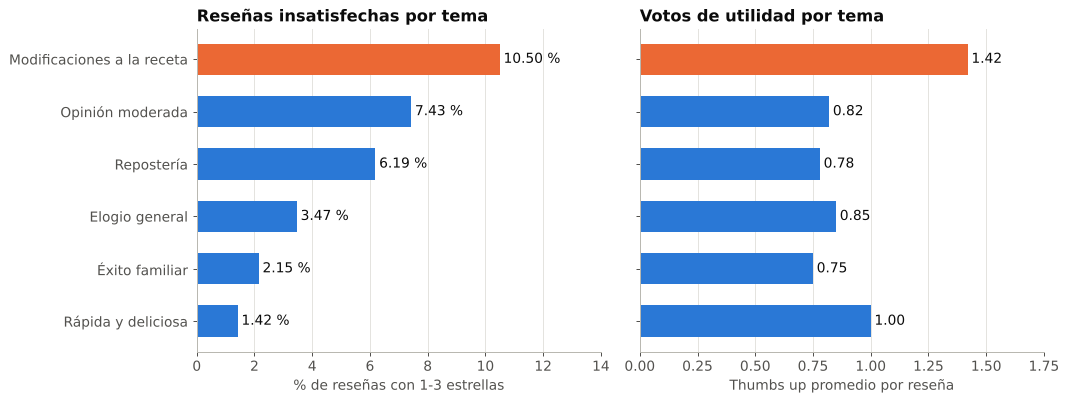

In [11]:
orden = perfil_temas.index[::-1]
colores = [NARANJA if t == "Modificaciones a la receta" else AZUL for t in orden]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for ax, columna, titulo, sufijo, xlabel in [
    (ax1, "pct_insatisfechas", "Reseñas insatisfechas por tema", " %", "% de reseñas con 1-3 estrellas"),
    (ax2, "thumbs_up_promedio", "Votos de utilidad por tema", "", "Thumbs up promedio por reseña"),
]:
    valores = truncar(perfil_temas.loc[orden, columna])
    barras = ax.barh(orden, valores.values, color=colores, height=0.6)
    ax.bar_label(barras, labels=[f"{v:.2f}{sufijo}" for v in valores.values], padding=3, color=TEXTO)
    paso = 2 if columna == "pct_insatisfechas" else 0.25
    tope = np.ceil(float(valores.max()) * 1.15 / paso) * paso
    ax.set_xlim(0, tope)
    ax.set_xticks(np.arange(0, tope + paso / 2, paso))
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", visible=False)
    ax.set_title(titulo)
fig.tight_layout()
guardar(fig, "fig05_temas_insatisfaccion_utilidad")
plt.show()

**Hallazgo 2.** Las reseñas del tema *Modificaciones a la receta* tienen **10.50 %** de insatisfacción, contra **1.42 %** de *Rápida y deliciosa*. La diferencia entre temas es significativa: Kruskal-Wallis sobre las estrellas (H = 734.55, p = 1.65e-156, ε² = 0.04) y χ² sobre el % de insatisfechas (χ² = 353.48, gl = 5, p = 3.10e-74).

Además, son las reseñas que más votos de utilidad reciben: **1.42** thumbs up en promedio contra 0.75-1.00 de los demás temas (Kruskal-Wallis p = 1.06e-24, aunque con efecto pequeño, ε² = 0.00).

**Lectura de negocio:** cuando una receta no funciona como está escrita, el usuario la ajusta, la califica peor y la comunidad considera útil su ajuste.

## 3. Hallazgo 3: 34 recetas concentran el riesgo

### 3.1 Perfil de cada receta

Se resume cada receta: número de reseñas, promedio de estrellas, % de reseñas insatisfechas, % de comentarios del tema *Modificaciones*, thumbs down promedio y **negatividad del texto** (probabilidad media de insatisfacción del Hallazgo 1, que también incluye los comentarios sin estrellas).

In [12]:
df["prob_insatisfaccion"] = pd.concat([calificadas["prob_insatisfaccion"], sin_calificacion["prob_insatisfaccion"]])
df["tema_modificacion"] = df["tema"] == "Modificaciones a la receta"

recetas = df.groupby("recipe_name").agg(
    numero_resenas=("comment_id", "count"),
    promedio_estrellas=("stars", lambda s: s[s > 0].mean()),
    pct_insatisfechas=("insatisfecha", "mean"),
    pct_modificaciones=("tema_modificacion", "mean"),
    thumbs_down_promedio=("thumbs_down", "mean"),
    negatividad_texto=("prob_insatisfaccion", "mean"),
)
recetas[["pct_insatisfechas", "pct_modificaciones", "negatividad_texto"]] *= 100

rho, p_rho = stats.spearmanr(recetas["negatividad_texto"], recetas["promedio_estrellas"])
print(f"Recetas: {len(recetas)}")
print(f"Spearman (negatividad del texto vs promedio de estrellas): rho = {truncar(rho):.2f}, p = {formato_p(p_rho)}")
display(tabla_truncada(recetas.describe().T[["mean", "min", "max"]]))

Recetas: 100
Spearman (negatividad del texto vs promedio de estrellas): rho = -0.75, p = 1.05e-19


,mean,min,max
numero_resenas,181.82,31.00,725.00
promedio_estrellas,4.71,4.44,4.95
pct_insatisfechas,6.54,0.84,14.63
pct_modificaciones,31.07,2.34,55.40
thumbs_down_promedio,0.58,0.02,2.19
negatividad_texto,18.23,9.99,31.20


La negatividad del texto y el promedio de estrellas tienen una correlación de Spearman de **ρ = −0.75** (p = 1.05e-19): a nivel receta, el indicador construido con el texto refleja la calificación y, además, toma en cuenta los comentarios que no tienen estrellas.

### 3.2 Elección del número de grupos

K-Means con las 6 variables estandarizadas (al número de reseñas y a los thumbs down se les aplica `log1p` por sus valores extremos).

,k,inercia,silueta
0,2,392.52,0.30
1,3,331.04,0.23
2,4,282.68,0.24
3,5,246.95,0.24
4,6,220.55,0.21
5,7,200.29,0.22
6,8,184.52,0.22


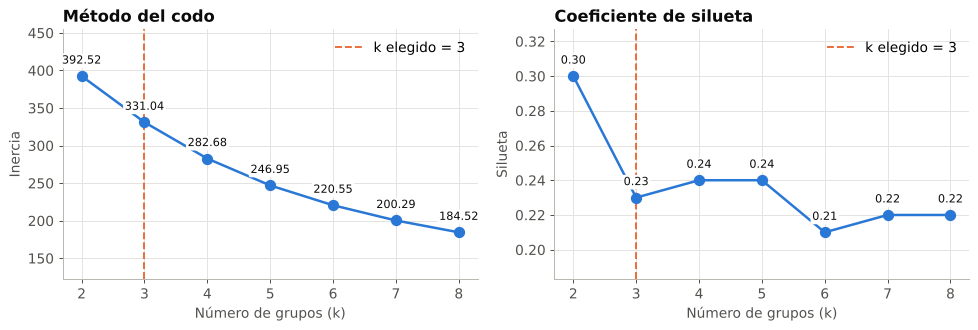

In [13]:
caracteristicas = ["promedio_estrellas", "pct_insatisfechas", "pct_modificaciones", "negatividad_texto",
                   "numero_resenas", "thumbs_down_promedio"]
X_recetas = recetas[caracteristicas].copy()
X_recetas[["numero_resenas", "thumbs_down_promedio"]] = np.log1p(X_recetas[["numero_resenas", "thumbs_down_promedio"]])
X_escalado = StandardScaler().fit_transform(X_recetas)

resultados_k = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=SEMILLA, n_init=20).fit(X_escalado)
    resultados_k.append({"k": k, "inercia": km.inertia_, "silueta": silhouette_score(X_escalado, km.labels_)})
resultados_k = pd.DataFrame(resultados_k)
display(tabla_truncada(resultados_k))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, columna, titulo in [(ax1, "inercia", "Método del codo"), (ax2, "silueta", "Coeficiente de silueta")]:
    valores = truncar(resultados_k[columna])
    ax.plot(resultados_k["k"], valores, color=AZUL, linewidth=2, marker="o", markersize=8)
    ax.axvline(3, color=NARANJA, linestyle="--", linewidth=1.5, label="k elegido = 3", zorder=1)
    for k, v in zip(resultados_k["k"], valores):
        ax.annotate(f"{v:.2f}", (k, v), textcoords="offset points", xytext=(0, 10), ha="center", fontsize=9,
                    color=TEXTO, bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none"), zorder=3)
    ax.legend(frameon=False, loc="upper right")
    ax.set_xticks(resultados_k["k"])
    ax.set_xlabel("Número de grupos (k)")
    ax.set_ylabel(columna.capitalize())
    margen = (valores.max() - valores.min()) * 0.3
    ax.set_ylim(valores.min() - margen, valores.max() + margen)
    ax.set_title(titulo)
fig.tight_layout()
guardar(fig, "fig06_eleccion_k")
plt.show()

La silueta máxima se obtiene con k = 2 (0.30), pero se elige **k = 3** (silueta 0.23): el grupo de riesgo es el mismo en ambos casos (se comprueba en la siguiente celda) y k = 3 además separa las recetas sin problemas en dos perfiles útiles para decidir. Una silueta de 0.23 indica grupos con separación débil: es una segmentación para gestión, no categorías naturales.

### 3.3 Segmentos de recetas

In [14]:
K_ELEGIDO = 3
kmeans = KMeans(n_clusters=K_ELEGIDO, random_state=SEMILLA, n_init=20).fit(X_escalado)
recetas["grupo"] = kmeans.labels_

perfil = recetas.groupby("grupo")[caracteristicas].mean()
# Nombre de cada grupo según su perfil
g_riesgo = perfil["promedio_estrellas"].idxmin()
restantes = perfil.drop(index=g_riesgo)
g_populares = restantes["numero_resenas"].idxmax()
g_estables = restantes.drop(index=g_populares).index[0]
nombres_grupo = {g_riesgo: "En riesgo", g_populares: "Populares consolidadas", g_estables: "Estables"}
recetas["segmento"] = recetas["grupo"].map(nombres_grupo)

perfil_segmentos = recetas.groupby("segmento").agg(
    recetas=("numero_resenas", "size"), **{c: (c, "mean") for c in caracteristicas})
perfil_segmentos = perfil_segmentos.loc[["Populares consolidadas", "Estables", "En riesgo"]]
display(tabla_truncada(perfil_segmentos))
print(f"Silueta con k = {K_ELEGIDO}: {truncar(silhouette_score(X_escalado, kmeans.labels_)):.2f}")

# Robustez: ¿el segmento "En riesgo" también aparece con k = 2 (el k de mayor silueta)?
kmeans_2 = KMeans(n_clusters=2, random_state=SEMILLA, n_init=20).fit(X_escalado)
recetas["grupo_k2"] = kmeans_2.labels_
grupo_bajo_k2 = recetas.groupby("grupo_k2")["promedio_estrellas"].mean().idxmin()
en_riesgo_k3 = recetas["segmento"] == "En riesgo"
coinciden = (en_riesgo_k3 & (recetas["grupo_k2"] == grupo_bajo_k2)).sum()
print(f"Recetas 'En riesgo' (k = 3) que también caen en el grupo de menor calificación con k = 2: "
      f"{coinciden} de {en_riesgo_k3.sum()}")

,recetas,promedio_estrellas,pct_insatisfechas,pct_modificaciones,negatividad_texto,numero_resenas,thumbs_down_promedio
segmento,,,,,,,
Populares consolidadas,33,4.77,4.59,39.49,16.20,229.36,0.68
Estables,33,4.78,4.72,18.93,16.67,175.45,0.23
En riesgo,34,4.58,10.19,34.67,21.71,141.85,0.82


Silueta con k = 3: 0.23
Recetas 'En riesgo' (k = 3) que también caen en el grupo de menor calificación con k = 2: 34 de 34


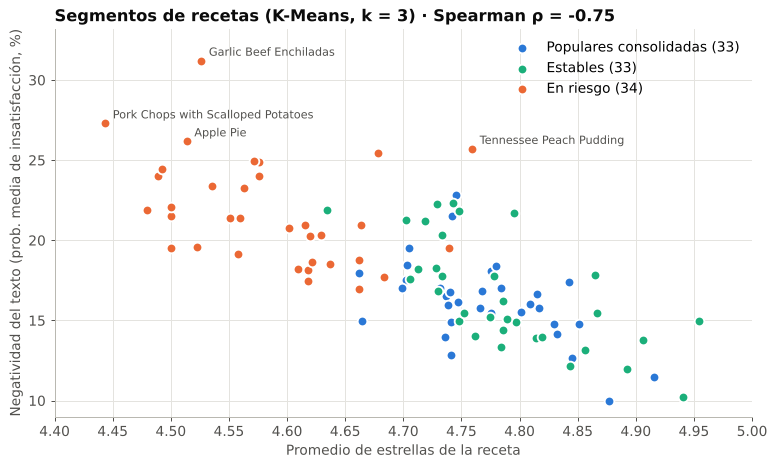

In [15]:
colores_segmento = {"Populares consolidadas": AZUL, "Estables": AQUA, "En riesgo": NARANJA}
fig, ax = plt.subplots(figsize=(10, 5.6))
for segmento, color in colores_segmento.items():
    sel = recetas[recetas["segmento"] == segmento]
    ax.scatter(sel["promedio_estrellas"], sel["negatividad_texto"], s=60, color=color,
               edgecolor="white", linewidth=1.5, label=f"{segmento} ({len(sel)})")
for nombre, fila in recetas[recetas["segmento"] == "En riesgo"].nlargest(4, "negatividad_texto").iterrows():
    ax.annotate(nombre, (fila["promedio_estrellas"], fila["negatividad_texto"]),
                textcoords="offset points", xytext=(6, 4), fontsize=9, color=TEXTO_2)
x_min, x_max = truncar(recetas["promedio_estrellas"].min()), recetas["promedio_estrellas"].max()
y_min, y_max = truncar(recetas["negatividad_texto"].min()), recetas["negatividad_texto"].max()
ax.set_xlim(x_min - 0.02, x_max + 0.04)
ax.set_ylim(y_min - 1, y_max + 2)
ax.set_xticks(np.round(np.arange(np.floor(x_min * 10) / 10, x_max + 0.05, 0.05), 2))
ax.set_xlabel("Promedio de estrellas de la receta")
ax.set_ylabel("Negatividad del texto (prob. media de insatisfacción, %)")
ax.set_title(f"Segmentos de recetas (K-Means, k = 3) · Spearman ρ = {truncar(rho):.2f}")
ax.legend(frameon=False, loc="upper right")
guardar(fig, "fig07_segmentos_recetas")
plt.show()

**Hallazgo 3.**

- **En riesgo (34 recetas):** 4.58★ en promedio, **10.19 %** de reseñas insatisfechas (más del doble que los otros dos grupos), la mayor negatividad del texto (21.71 %) y más thumbs down (0.82).
- **Populares consolidadas (33):** las de más reseñas (229.36 en promedio), 4.77★ y 39.49 % de comentarios con modificaciones: la gente las adapta, pero queda satisfecha.
- **Estables (33):** 4.78★, menos modificaciones (18.93 %) y casi sin thumbs down (0.23).

Las 34 recetas en riesgo también forman el grupo de menor calificación con k = 2, por lo que el segmento es robusto.

### 3.4 Lista de prioridad

,numero_resenas,promedio_estrellas,pct_insatisfechas,pct_modificaciones,negatividad_texto
recipe_name,,,,,
Cherry Bars,135,4.47,14.63,24.44,21.87
Cheeseburger Paradise Soup,100,4.52,14.44,41.00,19.60
Pork Chops with Scalloped Potatoes,157,4.44,13.38,37.57,27.29
First-Place Coconut Macaroons,145,4.49,13.28,41.37,24.46
Winning Apple Crisp,194,4.53,13.09,35.56,23.35
Apple Pie,241,4.51,12.84,42.73,26.17
Favorite Dutch Apple Pie,144,4.48,11.85,34.72,23.98
Lime Chicken Tacos,86,4.50,11.84,30.23,19.49
Strawberry Pretzel Salad,131,4.57,11.76,34.35,24.92


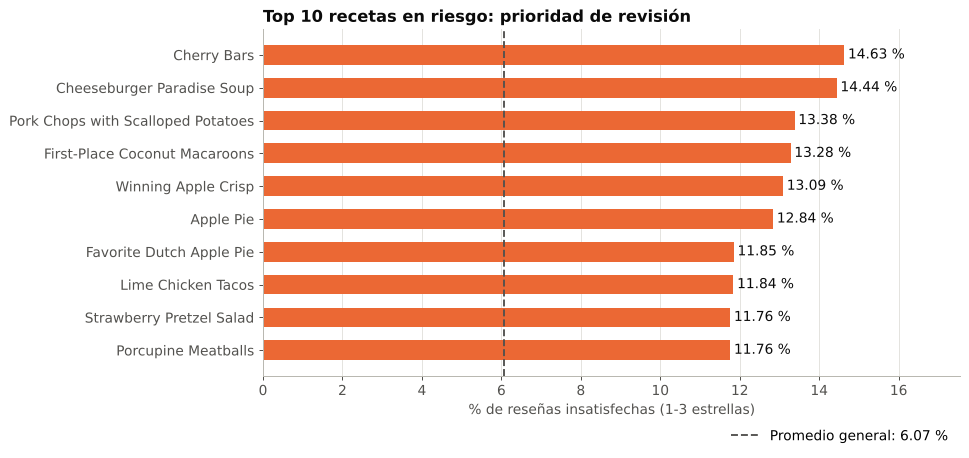

In [16]:
en_riesgo = (recetas[recetas["segmento"] == "En riesgo"]
             .sort_values("pct_insatisfechas", ascending=False)
             [["numero_resenas", "promedio_estrellas", "pct_insatisfechas", "pct_modificaciones", "negatividad_texto"]])
display(tabla_truncada(en_riesgo.head(10)))

top = truncar(en_riesgo["pct_insatisfechas"].head(10))[::-1]
fig, ax = plt.subplots(figsize=(10, 5))
barras = ax.barh(top.index, top.values, color=NARANJA, height=0.6)
ax.bar_label(barras, labels=[f"{v:.2f} %" for v in top.values], padding=3, color=TEXTO)
promedio_general = truncar(calificadas["insatisfecha"].mean() * 100)
ax.axvline(promedio_general, color=TEXTO_2, linestyle="--", linewidth=1.5,
           label=f"Promedio general: {promedio_general:.2f} %")
ax.legend(frameon=False, loc="upper right", bbox_to_anchor=(1.0, -0.12))
ax.set_xlim(0, float(top.max()) * 1.2)
ax.set_xticks(range(0, int(top.max() * 1.2) + 1, 2))
ax.set_xlabel("% de reseñas insatisfechas (1-3 estrellas)")
ax.grid(axis="y", visible=False)
ax.set_title("Top 10 recetas en riesgo: prioridad de revisión")
guardar(fig, "fig08_top_recetas_riesgo")
plt.show()

Las 10 recetas de la lista tienen entre **11.76 %** y **14.63 %** de reseñas insatisfechas, casi el doble o más del promedio general (6.07 %). Es la lista de trabajo para el equipo editorial.

## 4. Conclusiones y recomendaciones

1. **El promedio de estrellas no basta.** Con 4.73★ de promedio, el texto revela que los comentarios sin calificación tienen 2.12 veces más insatisfacción (19.07 % contra 8.97 %). **Recomendación:** usar el modelo de texto (AUC = 0.93) como indicador de satisfacción, incluyendo los comentarios sin estrellas.
2. **La insatisfacción se concentra en las recetas que la gente tiene que modificar** (10.50 % de insatisfechas en ese tema contra 1.42 % en *Rápida y deliciosa*), y quejas como *instructions* o *sweet* apuntan a la redacción y a las proporciones. **Recomendación:** revisar instrucciones y cantidades, y publicar como variantes oficiales los ajustes con más thumbs up.
3. **34 recetas forman el segmento en riesgo** (4.58★, 10.19 % de insatisfechas). **Recomendación:** empezar por *Cherry Bars*, *Cheeseburger Paradise Soup* y *Pork Chops with Scalloped Potatoes*.

**Limitaciones:** el modelo también marca algunas reseñas de 4-5★ que contienen críticas (precisión 0.51); los temas dependen del número elegido (6); la segmentación tiene separación débil (silueta 0.23).